The code uses the code from youngsoul's pyimagesearch-covid19-image-classification: https://github.com/youngsoul/pyimagesearch-covid19-image-classification

It also uses the dataset from the COVID19, Pneumonia and Normal Chest X-ray PA Dataset: https://data.mendeley.com/datasets/mxc6vb7svm/2

This notebook runs the whole project from a clean start. It adds the lung finder from Paper 3 (Bassi and Attux, 2022) and trains VGG16 on three versions of every X ray.

## Setup

In [ ]:
# Cleans everything so every run starts fresh.
%cd /content
!rm -rf covid_pneumonia_dataset
!rm -rf covid_pneumonia_dataset_wrapped
!rm -rf pyimagesearch-covid19-image-classification
!rm -rf lung_data
!rm -rf lung_quick
!rm -rf lung_test
#!rm -f covid_pneumonia_dataset.zip

/content


In [ ]:
# Get the classifier code from GitHub (or update it if it is already here)
%cd /content
REPO = "/content/pyimagesearch-covid19-image-classification"
import os
if os.path.exists(f"{REPO}/.git"):
    !git -C {REPO} pull
else:
    !git clone https://github.com/MarzSaod/pyimagesearch-covid19-image-classification
%cd {REPO}
!mkdir -p models model_performance
%cd /content

/content
Cloning into 'pyimagesearch-covid19-image-classification'...
remote: Enumerating objects: 517, done.
remote: Counting objects: 100% (68/68), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 517 (delta 37), reused 17 (delta 6), pack-reused 449 (from 1)
Receiving objects: 100% (517/517), 789.73 MiB | 26.66 MiB/s, done.
Resolving deltas: 100% (80/80), done.
Updating files: 100% (395/395), done.
/content/pyimagesearch-covid19-image-classification
/content


In [ ]:
# Downloads the dataset and unzips it into a fresh folder every time, so running this cell twice cannot double the images
%cd /content
import os, shutil, zipfile

mendeley_link = "https://data.mendeley.com/public-api/zip/mxc6vb7svm/download/2"
ZIP = "covid_pneumonia_dataset.zip"

if os.path.exists(ZIP) and zipfile.is_zipfile(ZIP):
    print("The zip file is already here, so the download is skipped.")
else:
    !wget -O {ZIP} "$mendeley_link"

shutil.rmtree("covid_pneumonia_dataset", ignore_errors=True)
with zipfile.ZipFile(ZIP) as z:
    z.extractall("covid_pneumonia_dataset")

for item in os.listdir("covid_pneumonia_dataset"):
    if item.endswith(".zip"):
        inner_path = os.path.join("covid_pneumonia_dataset", item)
        print(f"Found the dataset inside: {item}")
        with zipfile.ZipFile(inner_path) as inner_z:
            print(f"contains {len(inner_z.namelist())} items")
            inner_z.extractall("covid_pneumonia_dataset")
        os.remove(inner_path)

/content
--2026-10-19 21:55:21--  https://data.mendeley.com/public-api/zip/mxc6vb7svm/download/2
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/mxc6vb7svm-2.zip?X-Amz-Security-Token=IQoJb3JpZ2luX2VjEG4aCWV1LXdlc3QtMSJHMEUCIFnaJyRw0LfW23kpe%2FDri3lpIqdrooFxv662%2FsSuNmH2AiEA5Lp8Eae43nHJulRQg7RF6F2mLQz3SCW72yeKJYkwVrYqjAUINxAEGgwzNjcxNDczODM4MjUiDESxaLytAhHxfWdHAyrpBEAb9PscnugzXrXYg%2FGWMm7r83rDySOaSKVzVj4bqDeSf1dXq2Wi0k%2BnxUWbani075eF29E3xYnfv%2FT1ayLRWJadq9dntnGC9fyOe92ovicKajH9e4ILs5Yr7BqokkMfCGYOhLGea5KkK%2F8e31CymsSZOBeXAb2Y%2FcEySOv%2BCh%2FjmFXOnGSAoZuMVQcvCok%2FOA540Gpq71MKP3D4PbaI9NmzFar81V6ExE2d7OS7tae%2FOM0JwSAfCPo662L9uQgo7gq34H1HCY1UJ5f3CHQ4HxYrI5NRU2aJVBcxve6TIWYQSKYBC%2Bs35Ksf%2FF0S7tjwLbn%2BM%2F7No78AE8aNlwLeZwLsCUxpBbyA2c64h1e

In [ ]:
# to check the folders and image counts
import os

for root, dirs, files in os.walk("covid_pneumonia_dataset"):
    level = root.replace("covid_pneumonia_dataset", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/  ({len(files)} files)")

covid_pneumonia_dataset/  (0 files)
  pneumonia/  (2313 files)
  normal/  (2313 files)
  covid/  (2313 files)


In [ ]:
# to update folder configuration to match the github code
# This makes a fresh copy every time, so running it again never nests a folder inside itself.
import shutil

wrapped_root = "/content/covid_pneumonia_dataset_wrapped/all"
shutil.rmtree(wrapped_root, ignore_errors=True)
os.makedirs(wrapped_root)

for cls in ["covid", "normal", "pneumonia"]:
    src = f"/content/covid_pneumonia_dataset/{cls}"
    dst = f"{wrapped_root}/{cls}"
    assert os.path.exists(src), f"{src} is missing. Run the download cell above first."
    shutil.copytree(src, dst)

print("Data is ready at:", wrapped_root)

Data is ready at: /content/covid_pneumonia_dataset_wrapped/all


In [ ]:
import tensorflow as tf
print("GPU devices:", tf.config.list_physical_devices("GPU"))
import torch
print("Torch sees a GPU:", torch.cuda.is_available())

GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Torch sees a GPU: True


In [ ]:
# Paths
import sys, importlib, os
from IPython.display import Image, display

DATASET = "/content/covid_pneumonia_dataset_wrapped/all"
OUT = f"{REPO}/outputs"
RES = OUT
LUNG_DIR = "/content/lung_data"

# Safety checks
need = {
    "report_utils.py": "remove_nested_copies",
    "train_covid19.py": "--max_per_class",
    "lung_focus.py": "rough guess",
}
for fname, marker in need.items():
    path = f"{REPO}/{fname}"
    assert os.path.exists(path), f"{fname} is missing from your GitHub fork. Add it next to train_covid19.py."
    assert marker in open(path).read(), f"Your GitHub copy of {fname} is an old version. Upload the new {fname} to your fork, then run the git cell again."

sys.path.insert(0, REPO)
import report_utils as ru
importlib.reload(ru)
print("Code is up to date. Results will be saved in:", OUT)

Code is up to date. Results will be saved in: /content/pyimagesearch-covid19-image-classification/outputs


### Dataset check

In [ ]:
# Stops here if the dataset folder is wrong, so no time is lost on a bad training run
removed, kept = ru.remove_nested_copies(DATASET)
classes, files, labels, skipped = ru.list_dataset(DATASET)
counts = {c: int((labels == i).sum()) for i, c in enumerate(classes)}
print("Images per class:", counts, "| total:", len(files), "| skipped files:", dict(skipped))
extra = ru.duplicate_name_count(files, labels)
assert extra == 0, f"{extra} file names appear twice in one class. Run the cleanup and download cells again."
assert all(v == 2313 for v in counts.values()), "The dataset page lists 2313 images per class (6939 in total). Something is different here."
print("Dataset check passed.")

No copied folders found.
Images per class: {'covid': 2313, 'normal': 2313, 'pneumonia': 2313} | total: 6939 | skipped files: {}
Dataset check passed.


## Paper 3 lung finder

The lung finder is the lung segmentation model from Paper 3. For every X ray it marks which pixels belong to the lungs. We then save three versions of each X ray: the full image, the lungs only, and everything outside the lungs only.

### Lung finder

In [ ]:
# Finds the lungs in every X ray, then saves a lungs only copy and an outside the lungs only copy of the dataset
%cd {REPO}
!python lung_focus.py --dataset {DATASET} --outdir {LUNG_DIR}

/content/pyimagesearch-covid19-image-classification
[INFO] device: cuda
[INFO] 6939 images in 3 classes: ['covid', 'normal', 'pneumonia']
[INFO] downloading StackedNet.py ...
[INFO] StackedNet.py verified
[INFO] downloading SegmentationDNN.pt ...
[INFO] SegmentationDNN.pt verified
[INFO] lung finder: 96/6939 images, 47.4 images per second, about 2.4 minutes left
[INFO] lung finder: 640/6939 images, 74.7 images per second, about 1.4 minutes left
[INFO] lung finder: 1280/6939 images, 78.4 images per second, about 1.2 minutes left
[INFO] lung finder: 1920/6939 images, 79.0 images per second, about 1.1 minutes left
[INFO] lung finder: 2560/6939 images, 79.0 images per second, about 0.9 minutes left
[INFO] lung finder: 3200/6939 images, 79.0 images per second, about 0.8 minutes left
[INFO] lung finder: 3840/6939 images, 78.6 images per second, about 0.7 minutes left
[INFO] lung finder: 4480/6939 images, 78.2 images per second, about 0.5 minutes left
[INFO] lung finder: 5120/6939 images, 77.

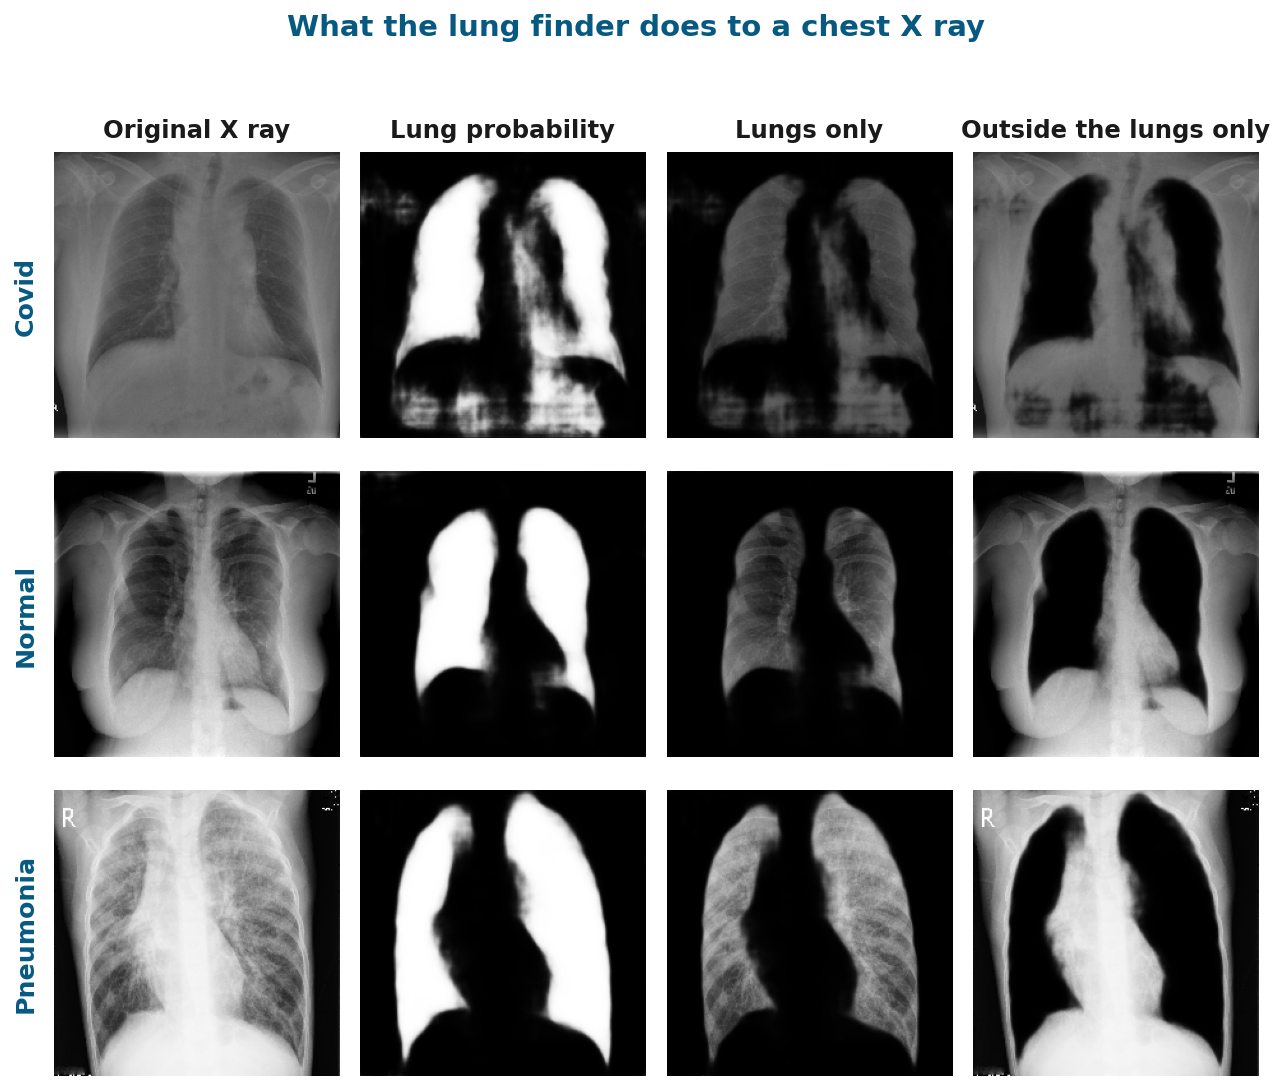

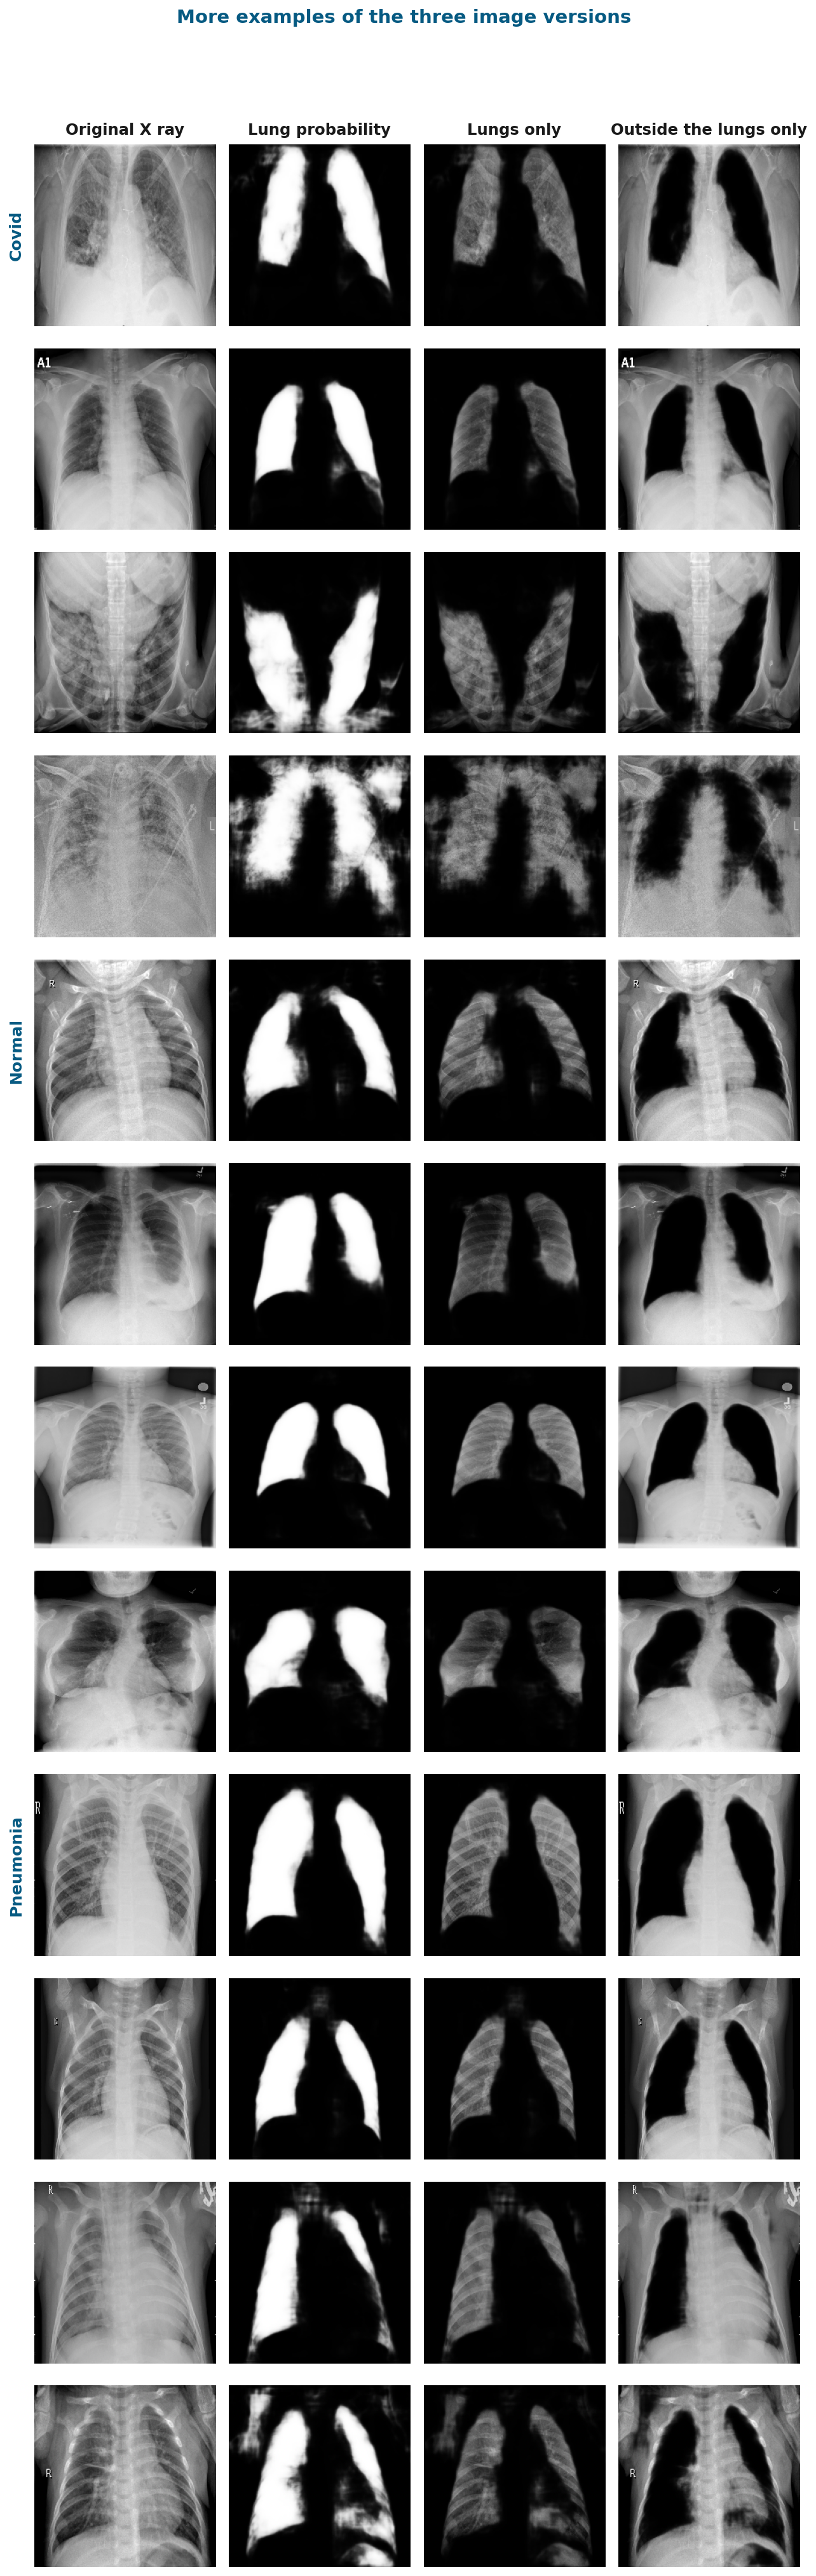

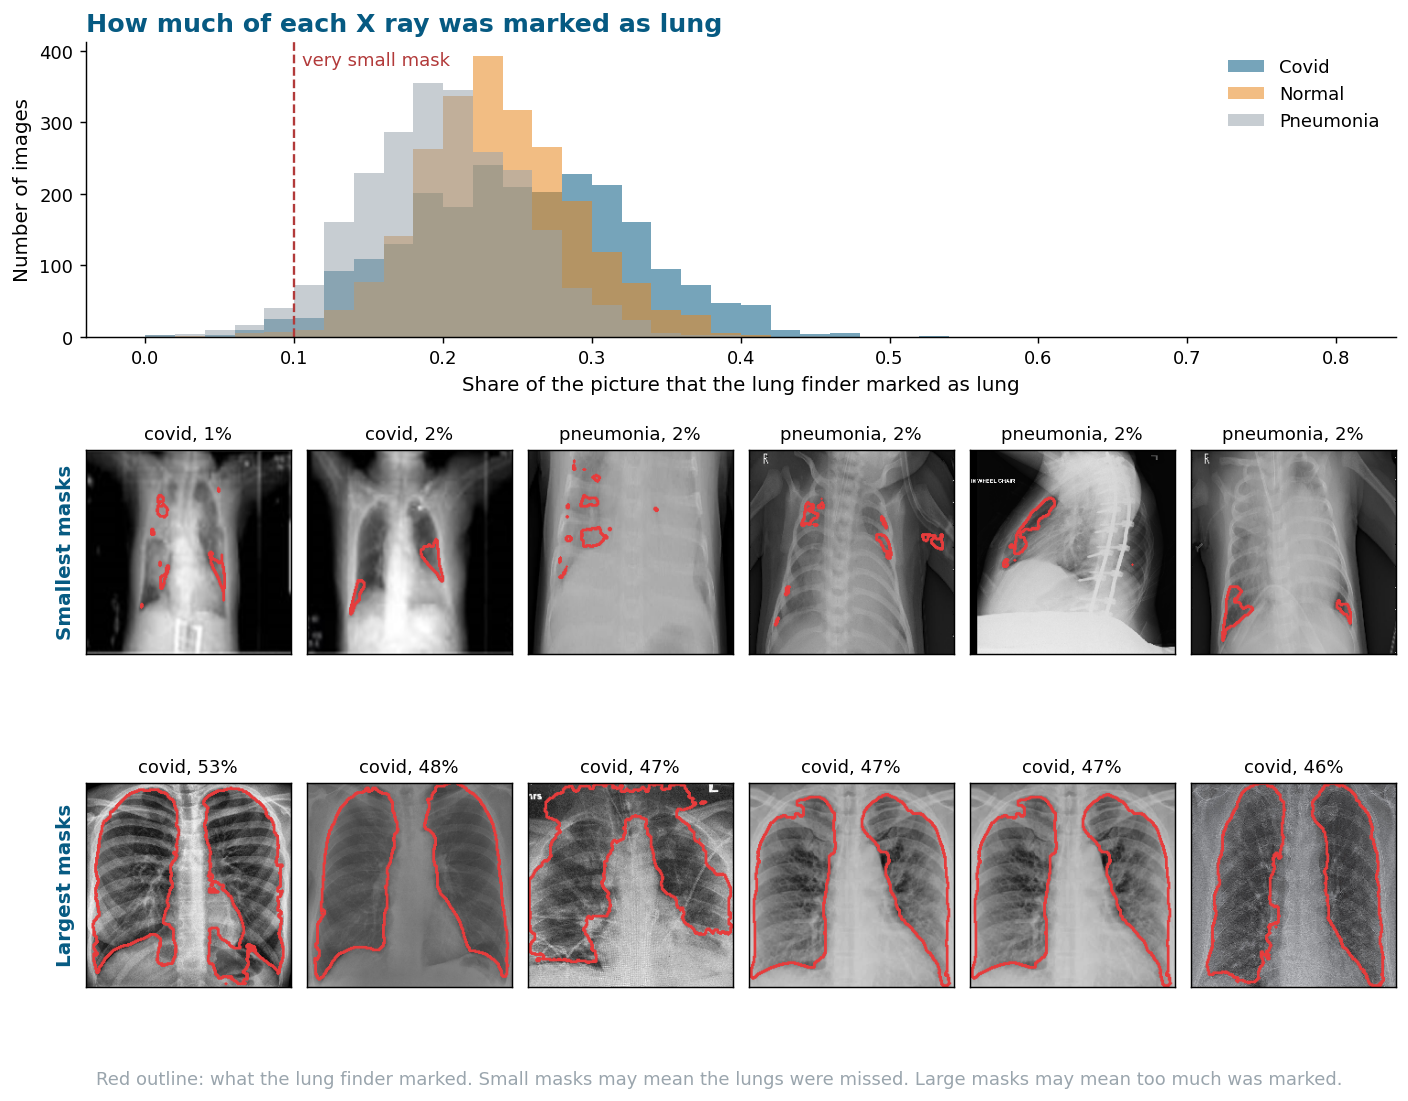

In [ ]:
display(Image(f"{LUNG_DIR}/lung_focus_preview.png"))
display(Image(f"{LUNG_DIR}/lung_focus_more.png"))
display(Image(f"{LUNG_DIR}/lung_focus_quality.png"))

## Training runs

Each run trains the same VGG16 on one version of the X rays, using the same split of 65 percent training, 20 percent validation, and 15 percent test images. Each run takes a while, and its results show up right below it in this notebook.

In [ ]:
LF_EP = 12
LF_BS = 32
FULL = DATASET
LUNG = f"{LUNG_DIR}/lung/all"
OUTSIDE = f"{LUNG_DIR}/outside/all"
COMMON = f"--models vgg16 --epochs {LF_EP} --batch_size {LF_BS} --pool global --split filename --val_frac 0.20 --test_frac 0.15 --outdir {RES}"
print(COMMON)

--models vgg16 --epochs 12 --batch_size 32 --pool global --split filename --val_frac 0.20 --test_frac 0.15 --outdir /content/pyimagesearch-covid19-image-classification/outputs


### Full image

/content/pyimagesearch-covid19-image-classification
Running Train COVID19 Models
Using dataset directory: /content/covid_pneumonia_dataset_wrapped/all
[INFO] found 6939 images in 3 classes: ['covid', 'normal', 'pneumonia']
[INFO] reading and resizing every image (a few minutes, only done once)...
[INFO] loaded 6939 images in 1.0 minutes, array size 1.04 GB
[INFO] saved cache file /content/covid_pneumonia_dataset_wrapped/image_cache_224.npz
---------------------------------------------------
Running Model: vgg16
[INFO] split mode filename: 4515 train, 1386 validation, 1038 test images
Class Labels: ['covid', 'normal', 'pneumonia']
W0000 00:00:1792447381.998161    5983 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[INFO] compiling model...
[INFO] training...
Epoch 1/12

Epoch 1: val_accuracy improved from None to 0.71284, saving m

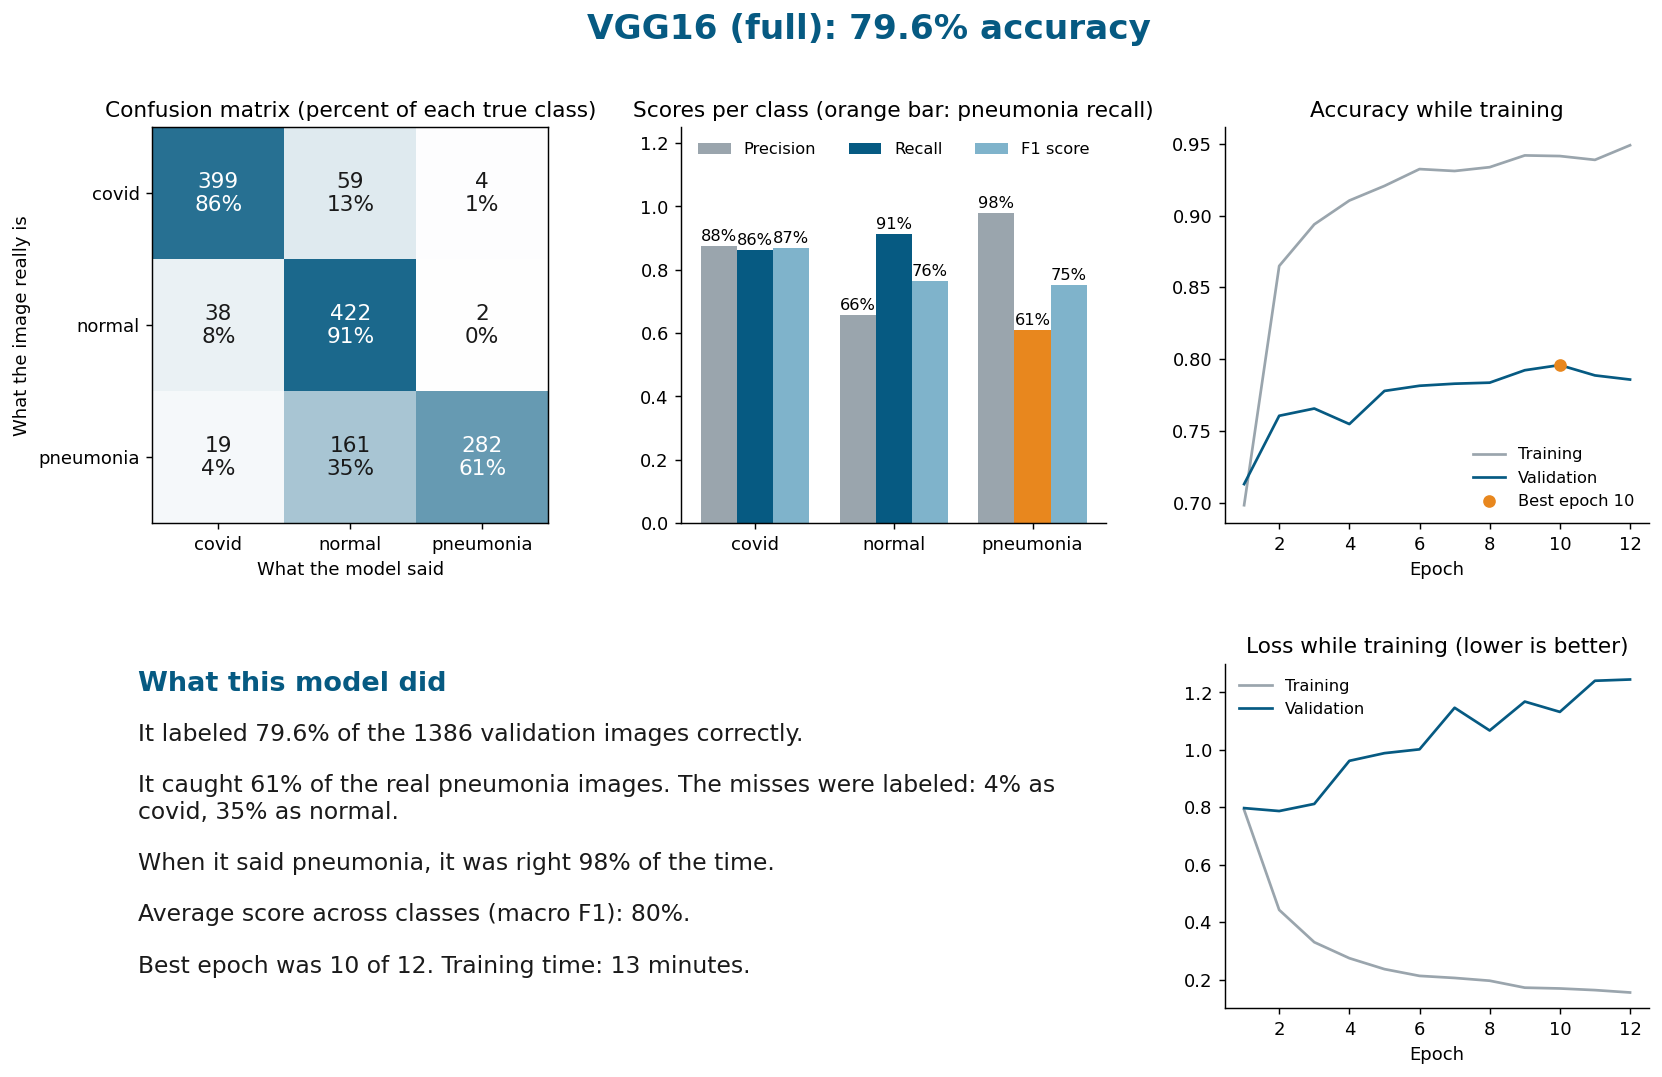

In [ ]:
%cd {REPO}
!python train_covid19.py --dataset {FULL} {COMMON} --run_name full
display(Image(ru.make_model_report(f"{RES}/vgg16_full")))

### Outside the lungs only

/content/pyimagesearch-covid19-image-classification
Running Train COVID19 Models
Using dataset directory: /content/lung_data/outside/all
[INFO] found 6939 images in 3 classes: ['covid', 'normal', 'pneumonia']
[INFO] reading and resizing every image (a few minutes, only done once)...
[INFO] loaded 6939 images in 0.2 minutes, array size 1.04 GB
[INFO] saved cache file /content/lung_data/outside/image_cache_224.npz
---------------------------------------------------
Running Model: vgg16
[INFO] split mode filename: 4515 train, 1386 validation, 1038 test images
Class Labels: ['covid', 'normal', 'pneumonia']
W0000 00:00:1792448216.494941   10238 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
[INFO] compiling model...
[INFO] training...
Epoch 1/12

Epoch 1: val_accuracy improved from None to 0.67532, saving model to /content/pyimagesearch-covid19-image-classification/outputs/vgg16_outsi

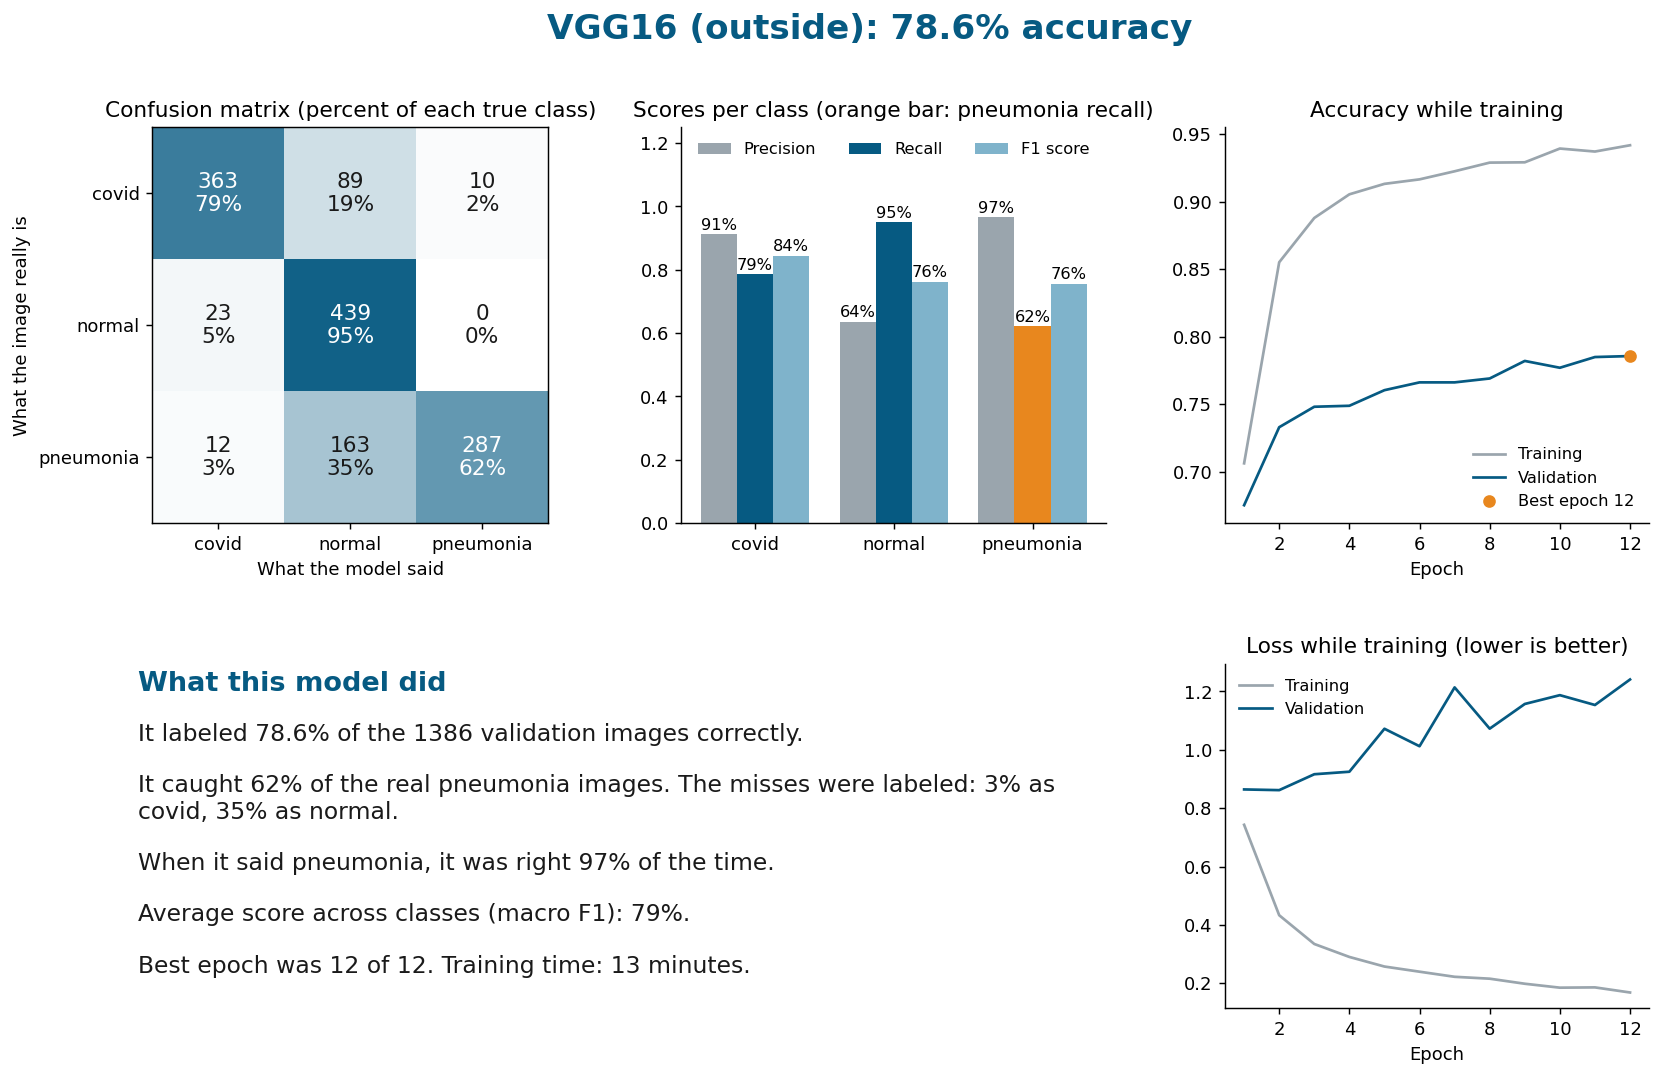

In [ ]:
%cd {REPO}
!python train_covid19.py --dataset {OUTSIDE} {COMMON} --run_name outside
display(Image(ru.make_model_report(f"{RES}/vgg16_outside")))

### Lungs only

/content/pyimagesearch-covid19-image-classification
Running Train COVID19 Models
Using dataset directory: /content/lung_data/lung/all
[INFO] found 6939 images in 3 classes: ['covid', 'normal', 'pneumonia']
[INFO] reading and resizing every image (a few minutes, only done once)...
[INFO] loaded 6939 images in 0.2 minutes, array size 1.04 GB
[INFO] saved cache file /content/lung_data/lung/image_cache_224.npz
---------------------------------------------------
Running Model: vgg16
[INFO] split mode filename: 4515 train, 1386 validation, 1038 test images
Class Labels: ['covid', 'normal', 'pneumonia']
W0000 00:00:1792449054.750426   14311 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
[INFO] compiling model...
[INFO] training...
Epoch 1/12
W0000 00:00:1792449058.177631   14464 cpu_allocator_impl.cc:82] Allocation of 19267584 exceeds 10% of free system memory.
W0000 00:00:1792449058.70

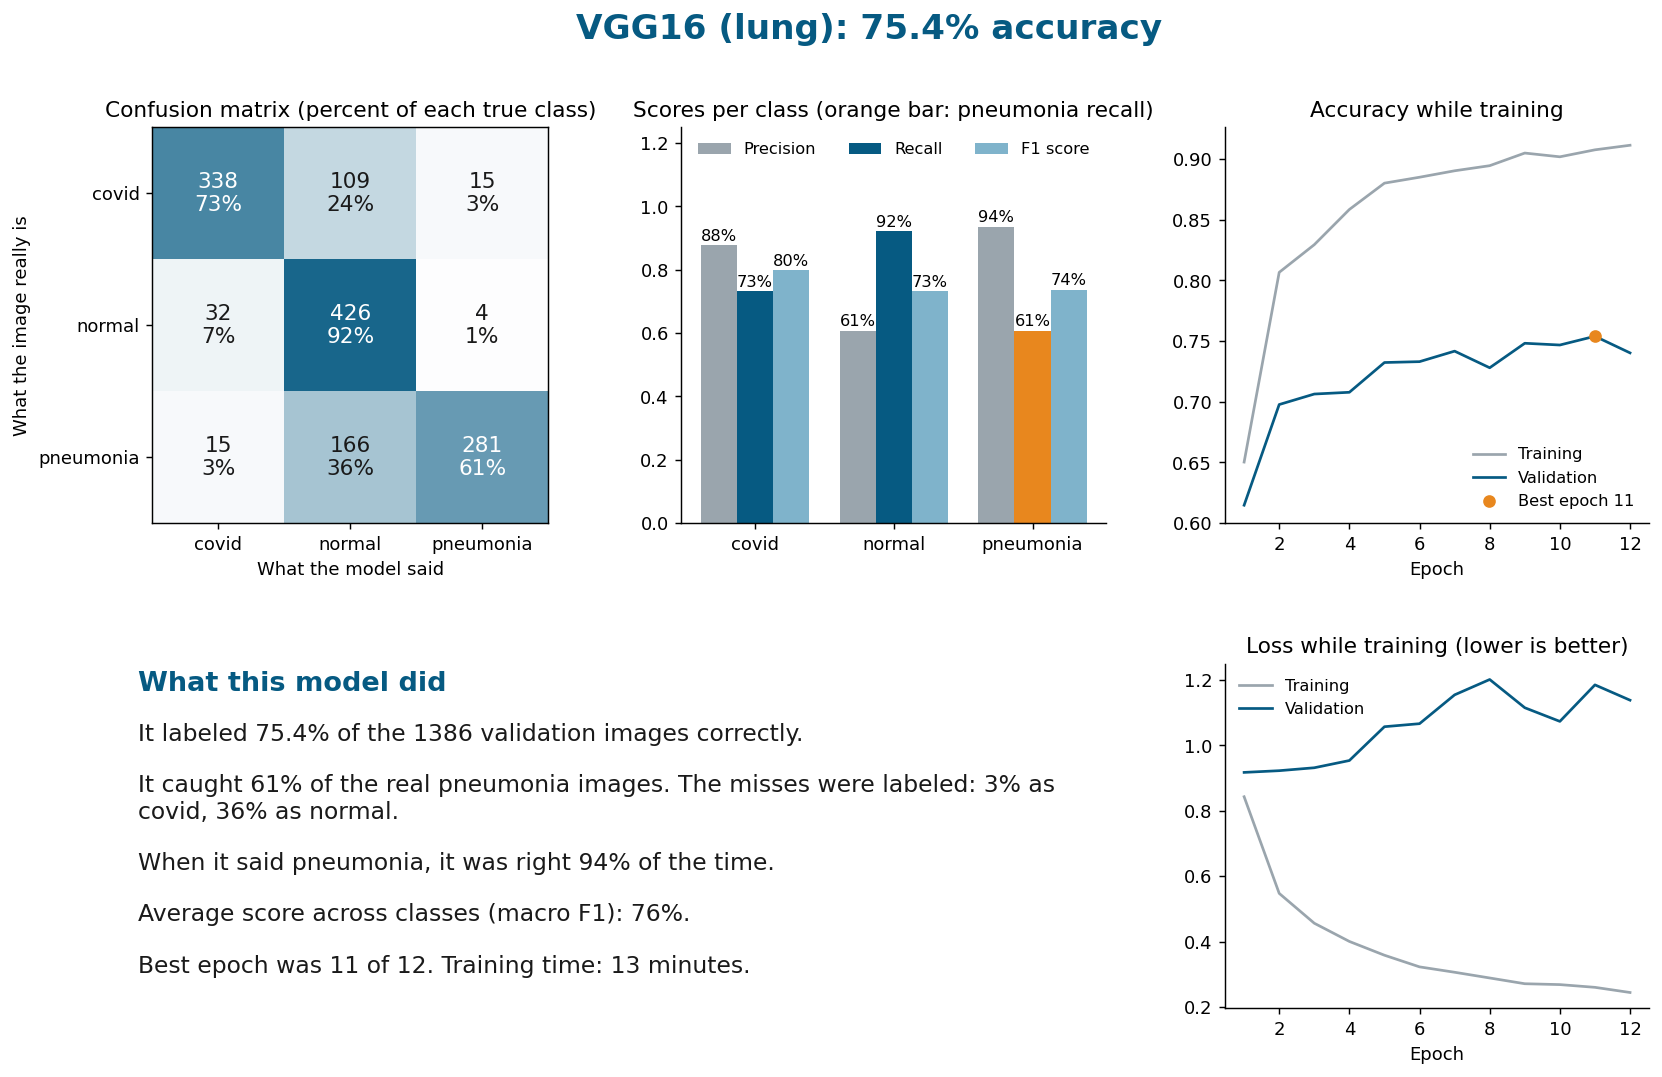

In [ ]:
%cd {REPO}
!python train_covid19.py --dataset {LUNG} {COMMON} --run_name lung
display(Image(ru.make_model_report(f"{RES}/vgg16_lung")))

## Results

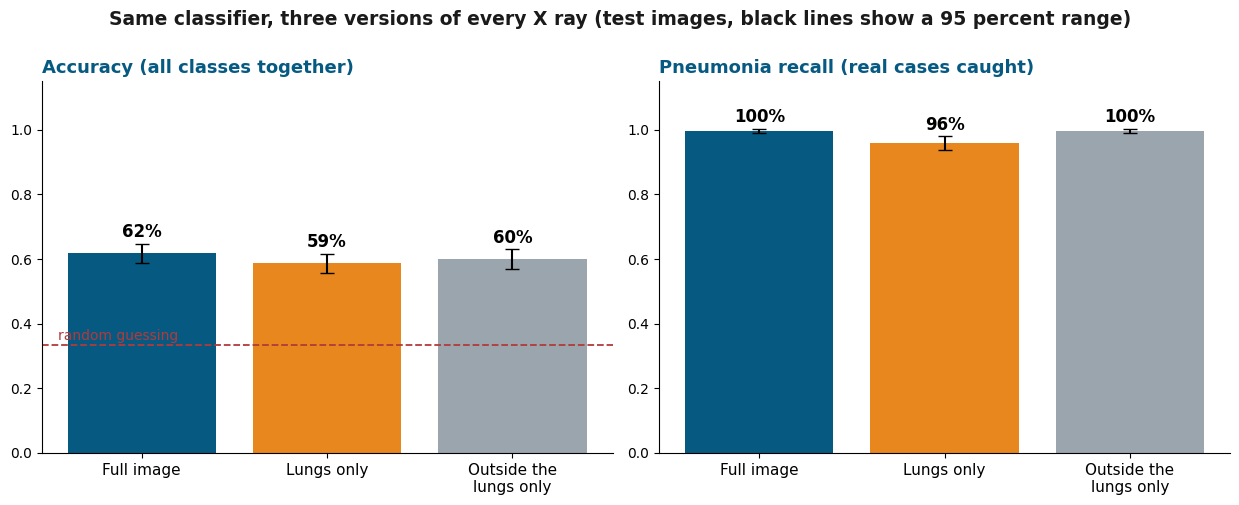

,Images,Set,Accuracy,Accuracy range,Pneumonia recall,Recall range
Version,,,,,,
Full image,1038,test,61.8%,3.0%,99.7%,0.6%
Lungs only,1038,test,58.7%,3.0%,96.0%,2.1%
Outside the lungs only,1038,test,60.0%,3.0%,99.7%,0.6%


In [ ]:
RUNS = {"Full image": f"{RES}/vgg16_full", "Lungs only": f"{RES}/vgg16_lung", "Outside the lungs only": f"{RES}/vgg16_outside"}
summary = ru.variant_summary(RUNS, out_png=f"{RES}/lung_focus_summary.png")
display(summary.style.format({"Accuracy": "{:.1%}", "Accuracy range": "{:.1%}", "Pneumonia recall": "{:.1%}", "Recall range": "{:.1%}"}))

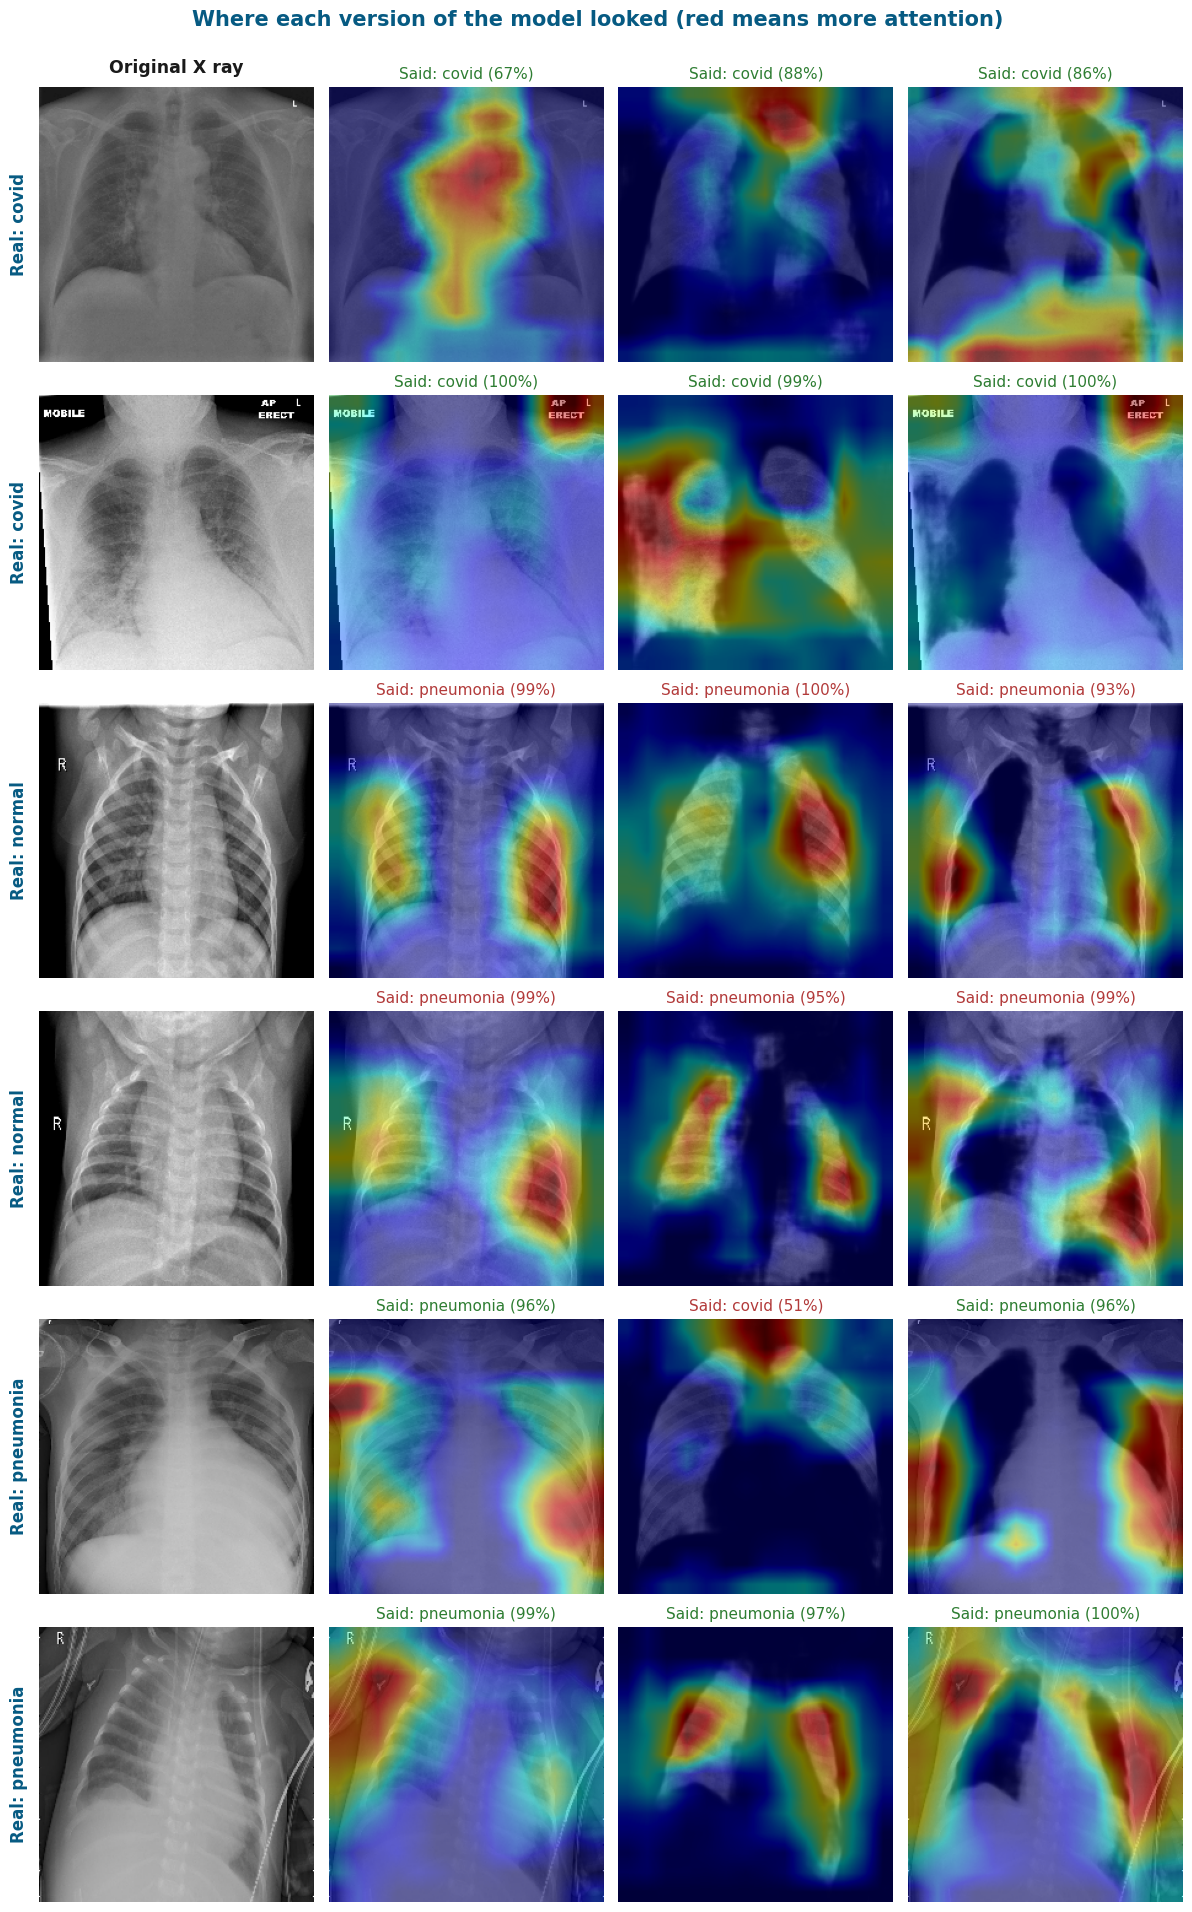

In [ ]:
_ = ru.gradcam_variants(RUNS, per_class=2, out_png=f"{RES}/lung_focus_gradcam.png")

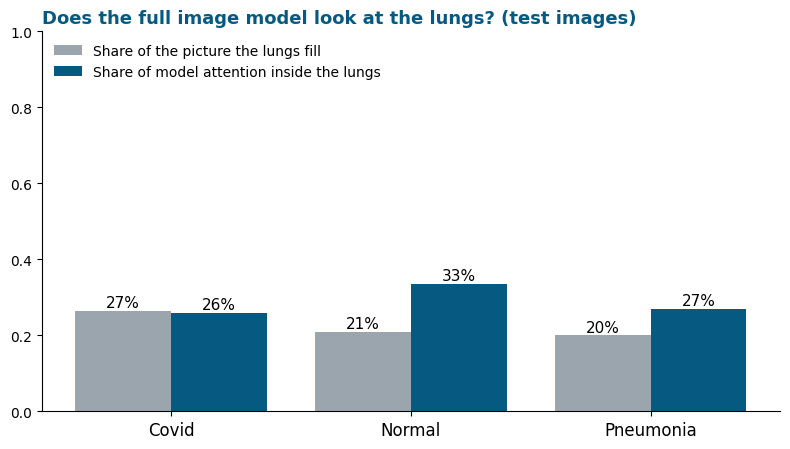

,Images,Lungs fill,Attention inside lungs,Ratio
Class,,,,
covid,100,27%,26%,0.98
normal,100,21%,33%,1.59
pneumonia,100,20%,27%,1.34


In [ ]:
share = ru.gradcam_lung_share(RUNS["Full image"], f"{LUNG_DIR}/masks.npz", per_class=100, out_png=f"{RES}/lung_share.png")
display(share.style.format({"Lungs fill": "{:.0%}", "Attention inside lungs": "{:.0%}", "Ratio": "{:.2f}"}))

### Scoreboard

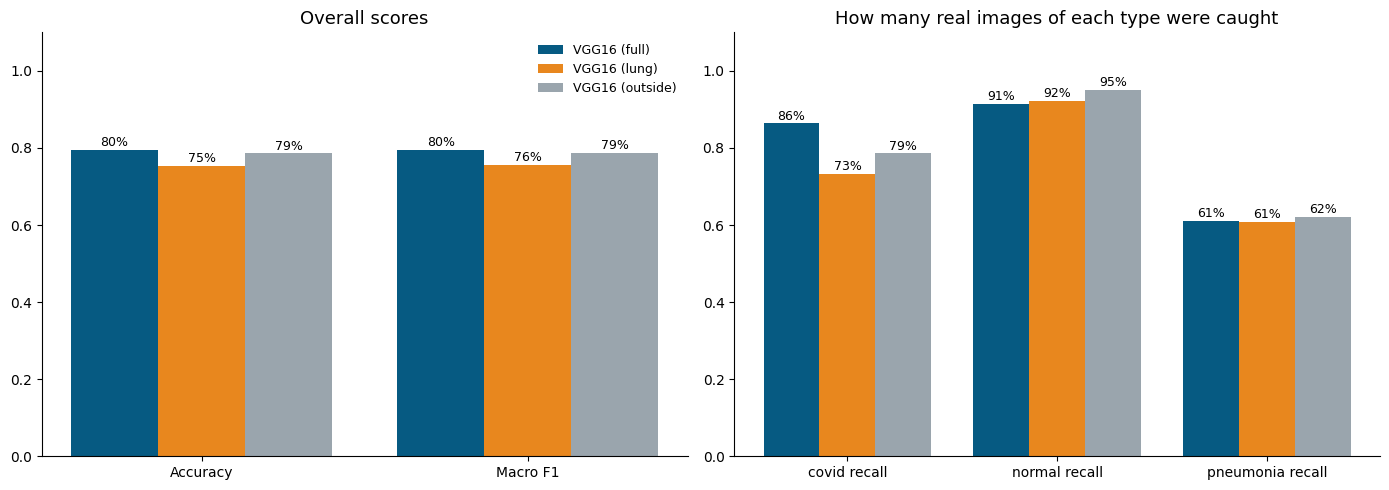

,Accuracy,Macro F1,Covid recall,Normal recall,Pneumonia recall,Pneumonia precision,Pneumonia called covid,Pneumonia called normal,Test accuracy,Test pneumonia recall
Run,,,,,,,,,,
VGG16 (full),79.6%,79.5%,86.4%,91.3%,61.0%,97.9%,0.041126,0.348485,61.8%,99.7%
VGG16 (lung),75.4%,75.6%,73.2%,92.2%,60.8%,93.7%,0.032468,0.359307,58.7%,96.0%
VGG16 (outside),78.6%,78.7%,78.6%,95.0%,62.1%,96.6%,0.025974,0.352814,60.0%,99.7%


In [ ]:
df = ru.compare_runs(ru.find_runs(RES))
display(df.style.format("{:.1%}", subset=[c for c in df.columns if "called" not in c]).background_gradient(cmap="Blues", axis=None))

## Extra checks

These checks use the full image run. They look at image sources and at near copies between training and validation, which could make scores look better than they are. They run last so a problem here cannot affect the main results above.

In [ ]:
import pandas as pd
RUN_FULL = f"{RES}/vgg16_full"
table, sizes, _ = ru.source_check(RUN_FULL)
display(table)
display(sizes.style.format({"share of images with it": "{:.0%}"}))

,width,height,mean_brightness,dark_border_share,count
outcome,,,,,
covid -> covid,1024.0,913.0,147.03,0.08,399
normal -> normal,1024.0,1024.0,132.65,0.41,422
pneumonia -> pneumonia,1168.0,796.0,123.38,0.95,282
pneumonia -> normal,1024.0,1024.0,119.92,0.60,161


,different image sizes,most common size,share of images with it
class,,,
covid,376,1200x1200,8%
normal,1,1024x1024,100%
pneumonia,281,1024x1024,38%


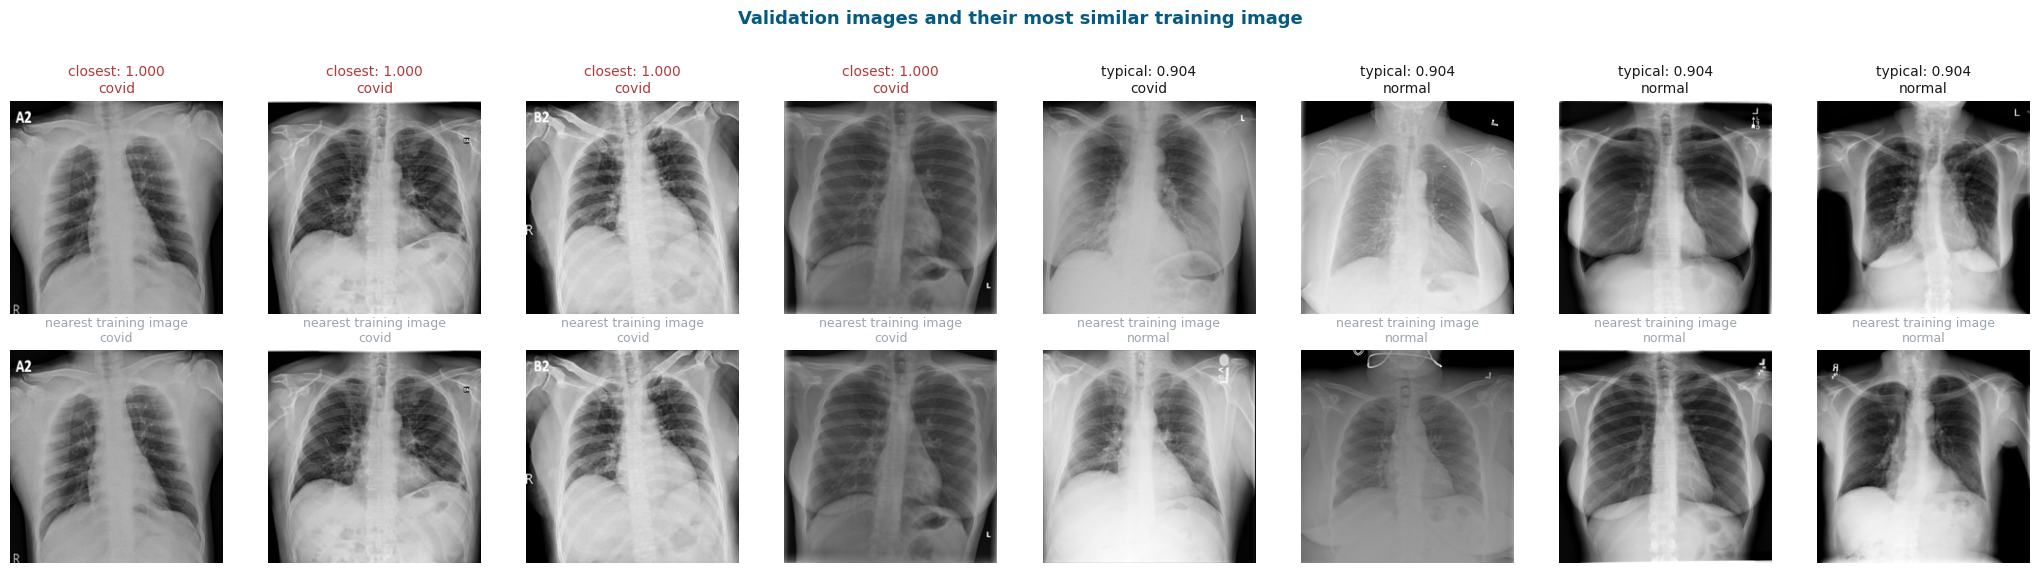

,val images with a near copy in training,share of validation,accuracy on those,accuracy on the rest
similarity at least,,,,
0.990000,95,6.9%,89.5%,78.9%
0.980000,98,7.1%,89.8%,78.8%
0.950000,143,10.3%,90.2%,78.4%
0.900000,745,53.8%,78.3%,81.1%


,median,p90,share_above_098
class,,,
covid,0.892,1.000,0.212
normal,0.903,0.933,0.000
pneumonia,0.913,0.947,0.000


In [ ]:
tab, per_class, png = ru.duplicate_check(DATASET, RUN_FULL)
display(tab.style.format({"share of validation": "{:.1%}", "accuracy on those": "{:.1%}", "accuracy on the rest": "{:.1%}"}))
display(per_class.round(3))